# Assignment 2 Distribution Grid Simulation

## Notebook B

### Task 1

- Create with pandapower the distribution grid depicted below in figure 1
- Ressources:
    - online docs https://pandapower.readthedocs.io/en/latest/index.html
- the lines, loads, and gens are qualitatively the same as in notebook A! Just the layout changed!

### Task 2

- Load the Dataset B for generation and load and perform a time series simulation.
- Ressources:
    - https://pandapower.readthedocs.io/en/latest/timeseries.html

### Task 3

- Explore how the allocation of the loads and generating elements influence the lines and external grid
- Now focus more on how to reasonably quantify the "goodness" of specific allocations, especially with regard line loading and external grid power


### Task 4
- upload your optimized allocations on moodle, use the format specified in the evaluation notebook

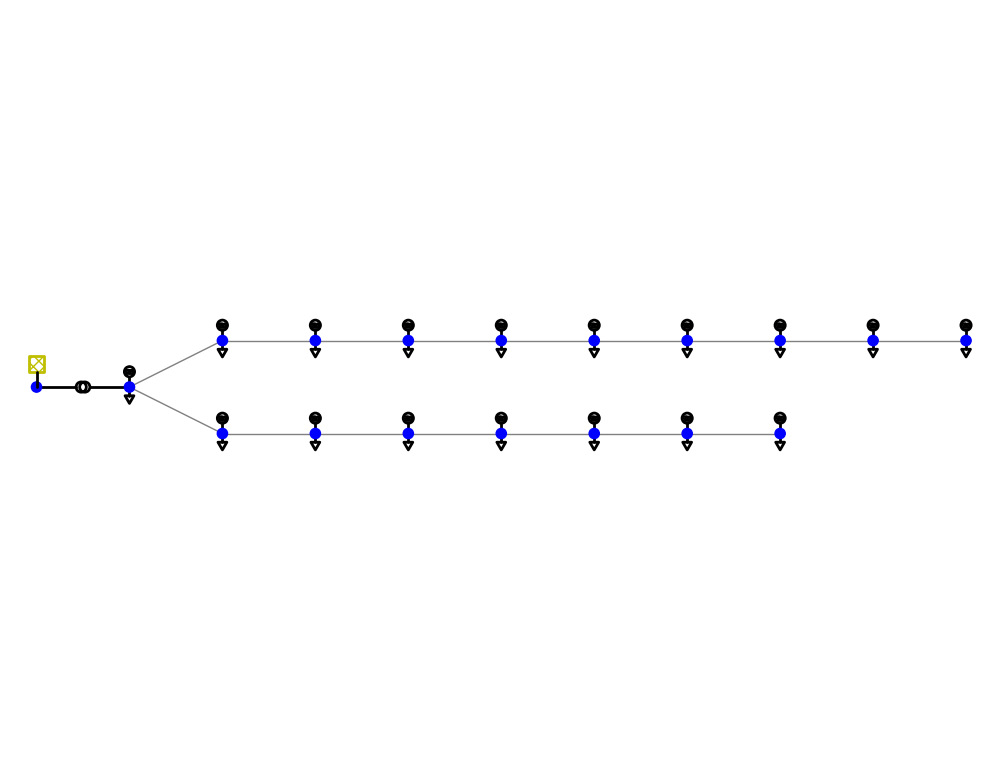

In [115]:
import pandapower as pp
import pandapower.plotting as plot
import pandas as pd
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

#### Creating the B Dataset Grid Using Pandapower

```python

In [116]:
# create empty net
net = pp.create_empty_network()

# create buses 0..17 (bus 0 is 20 kV, the rest are 0.4 kV)
buses = [pp.create_bus(net, vn_kv=20.0 if i==0 else 0.4, name=f"Bus {i}") for i in range(18)]

# create bus elements (use the first few buses as examples)
pp.create_ext_grid(net, bus=buses[0], vm_pu=1.02, name="Grid Connection")
for i in range(1, 18):
    pp.create_load(net, bus=buses[i], p_mw=0.1, q_mvar=0.005, name=f"Load {i}")
    pp.create_sgen(net, bus=buses[i], p_mw=0.1, q_mvar=0.005, name=f"Sgen {i}")


# create branch elements
tid = pp.create_transformer(
    net, hv_bus=buses[0], lv_bus=buses[1], std_type="0.4 MVA 20/0.4 kV", name="Trafo"
)
# create primary branch: buses 1 -> 2 -> ... -> 8
for i in range(1, 8):
    pp.create_line(net, from_bus=buses[i], to_bus=buses[i+1], length_km=0.100, name=f"Line {i}-{i+1}", std_type="NAYY 4x50 SE")

# create second branch: connect bus 1 to bus 9, then 9 -> 10 -> ... -> 17
pp.create_line(net, from_bus=buses[1], to_bus=buses[9], length_km=0.100, name="Line 1-9", std_type="NAYY 4x50 SE")
for i in range(9, 17):
    pp.create_line(net, from_bus=buses[i], to_bus=buses[i+1], length_km=0.100, name=f"Line {i}-{i+1}", std_type="NAYY 4x50 SE")

No or insufficient geodata available --> Creating artificial coordinates. This may take some time


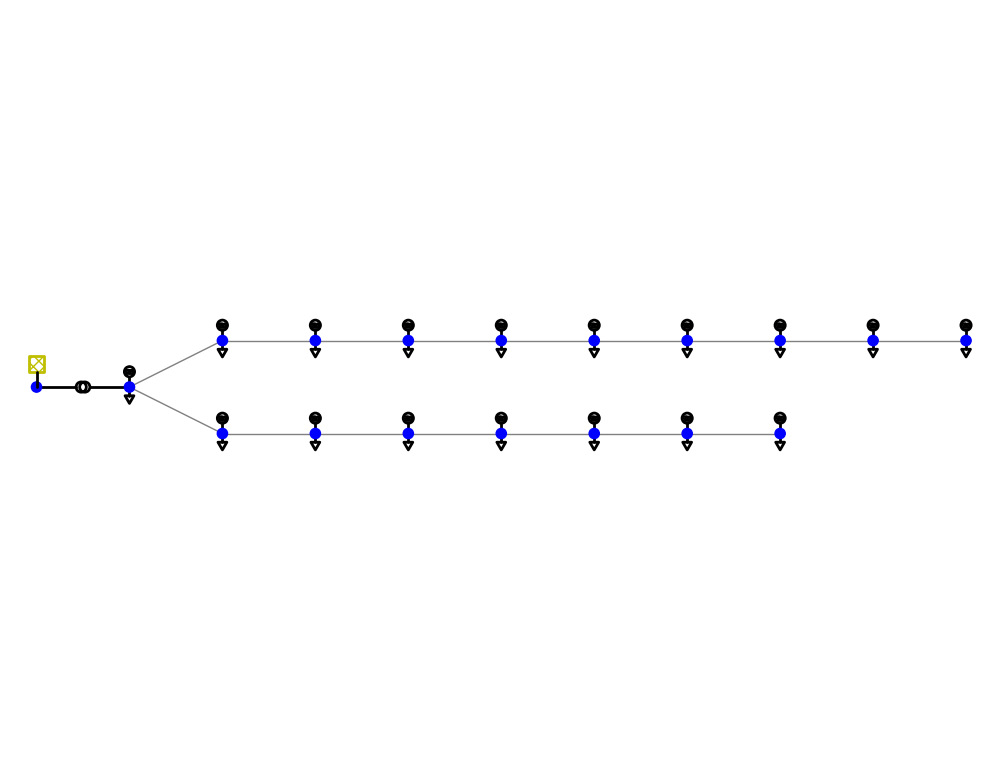

<Axes: >

In [117]:
plot.simple_plot(net, plot_loads=True, plot_sgens=True)

In [118]:
pp.runpp(net)
net.res_ext_grid

,p_mw,q_mvar
0,0.001405,-0.000017


The plotted grid looks identical to the provided figure and has all the same features as the example given in dataset A, confirming the correct creation of the distribution grid using pandapower.

#### Dataset B Data analysis and visualization

In [119]:
# load the dataframes from csv files
gen_data = pd.read_csv("../Data/GenerationData_B.csv", index_col=0)
gen_data.columns.name = "household"
load_data = pd.read_csv("../Data/LoadData_B.csv", index_col=0)
load_data.columns.name = "household"
load_data

household,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,0.000166,0.000163,0.000162,0.000136,0.000177,0.000401,0.000175,0.000154,0.000151,0.000172,0.000173,1.201822e-04,0.000169,0.000161,0.000204,0.000201,0.000178
1,0.000161,0.000170,0.000147,0.000179,0.000162,0.000166,0.000270,0.000146,0.000149,0.000164,0.000141,1.595255e-04,0.000180,0.000140,0.000207,0.000213,0.000188
2,0.000172,0.000161,0.000161,0.000175,0.000239,0.000179,0.000163,0.000151,0.000151,0.000146,0.000143,1.524271e-04,0.000183,0.000199,0.000203,0.000204,0.000166
3,0.000162,0.000181,0.000148,0.000166,0.000197,0.000172,0.000179,0.000154,0.000159,0.000149,0.000147,1.791680e-04,0.000189,0.000156,0.000200,0.000199,0.000182
4,0.000168,0.000173,0.000159,0.000158,0.000156,0.000177,0.000169,0.000142,0.000148,0.000130,0.000138,1.390596e-04,0.000173,0.000163,0.000203,0.000180,0.000182
5,0.000171,0.000323,0.000162,0.000284,0.000169,0.000181,0.000150,0.000163,0.000287,0.000183,0.000169,1.677572e-04,0.000210,0.000156,0.000216,0.000205,0.000191
6,0.000167,0.000180,0.000101,0.000094,0.000198,0.000186,0.000163,0.000140,0.000170,0.000236,0.000279,9.238272e-05,0.000114,0.000105,0.000179,0.000224,0.000097
7,0.000131,0.000143,0.000182,0.000097,0.000190,0.000186,0.000106,0.000129,0.000206,0.000113,0.001041,2.908175e-04,0.000357,0.000329,0.000345,0.000293,0.000258
8,0.000120,0.000192,0.000066,0.000058,0.000231,0.000199,0.000111,0.000177,0.000211,0.000011,0.000489,4.350185e-04,0.000507,0.000465,0.000301,0.000348,0.000395
9,0.000279,0.000225,0.000444,0.000277,0.000264,0.000258,0.000282,0.000462,0.000239,0.000413,0.000155,4.019233e-04,0.000418,0.000453,0.000313,0.000337,0.000370


Firstly, we simply plot the load and generation data separately using stacked plots to visualize the consumption and generation patterns over time.

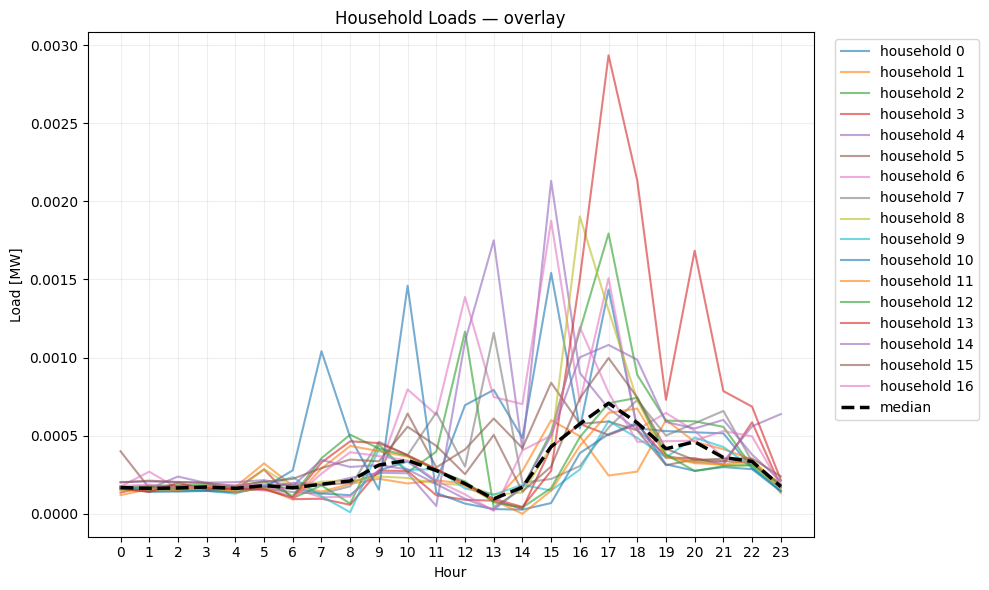

In [120]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
for col in load_data.columns:
    plt.plot(load_data.index, load_data[col], alpha=0.6, label=f"household {col}")
# Add median across households
median_load = load_data.median(axis=1)
plt.plot(load_data.index, median_load, color='black', linewidth=2.5, linestyle='--', label='median', zorder=10)
plt.xlabel("Hour")
plt.ylabel("Load [MW]")
plt.title("Household Loads — overlay")
plt.xticks(range(0,24))
plt.legend(ncol=1, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

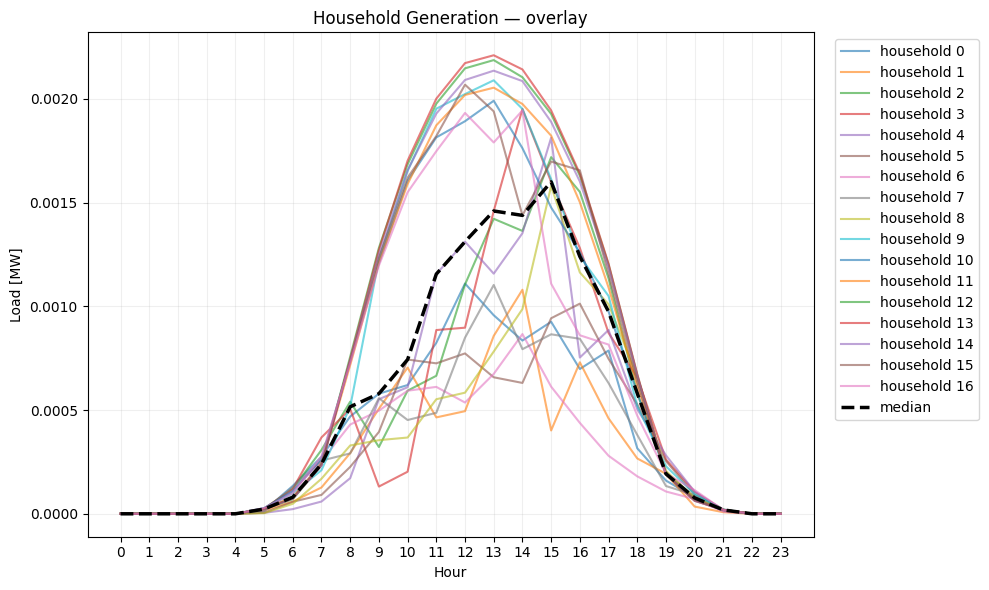

In [121]:
plt.figure(figsize=(10,6))
for col in gen_data.columns:
    plt.plot(gen_data.index, gen_data[col], alpha=0.6, label=f"household {col}")
# Add median across households
median_gen = gen_data.median(axis=1)
plt.plot(gen_data.index, median_gen, color='black', linewidth=2.5, linestyle='--', label='median', zorder=10)
plt.xlabel("Hour")
plt.ylabel("Load [MW]")
plt.title("Household Generation — overlay")
plt.xticks(range(0,24))
plt.legend(ncol=1, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

As we can see there is a wide range for the load values, with some households consuming significantly more power than others. The generation data also shows variability, with certain households generating more power at specific times, however the overall generation follows the typical daily pattern of solar generation, peaking during midday hours. It's also important to note that the median load peaks don't align perfectly with the generation peaks, and the peak load values are generally lower than the peak generation values.

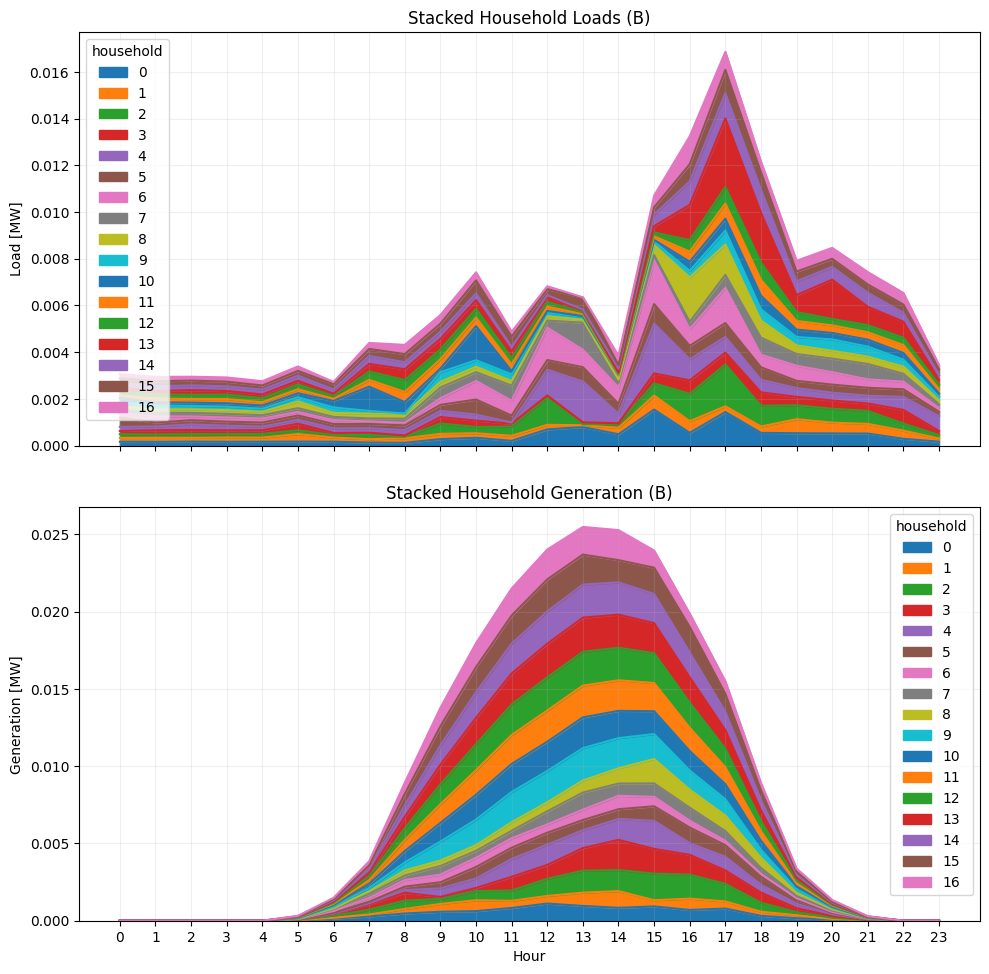

In [122]:
# Separate stacked plots: loads vs generation (Dataset B)
import matplotlib.pyplot as plt

# Ensure the dataframes 'load_data' and 'gen_data' exist from earlier cells
# Create two vertical subplots that share the x-axis
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Stacked loads
load_data.plot.area(ax=axes[0], stacked=True, title="Stacked Household Loads (B)")
axes[0].set_ylabel("Load [MW]")
axes[0].grid(alpha=0.2)

# Stacked generation (sgen)
gen_data.plot.area(ax=axes[1], stacked=True, title="Stacked Household Generation (B)")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Generation [MW]")
axes[1].set_xticks(range(0,24))
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

The stacked plots are a good way to visualize which households contribute most to the overall load and generation at different times, and shows the overall trends clearly. It can be noted that during peak generation hours, the total generation significantly exceeds even the peak total load, indicating that peak generation times might be the times when the lines are most overloaded. To explore this further we check how much of the generated power is actually consumed locally versus being exported to the grid. 

<Axes: title={'center': 'Load and Generation Data Household 13'}, xlabel='Time of the Day [h]', ylabel='Generation [MW]'>

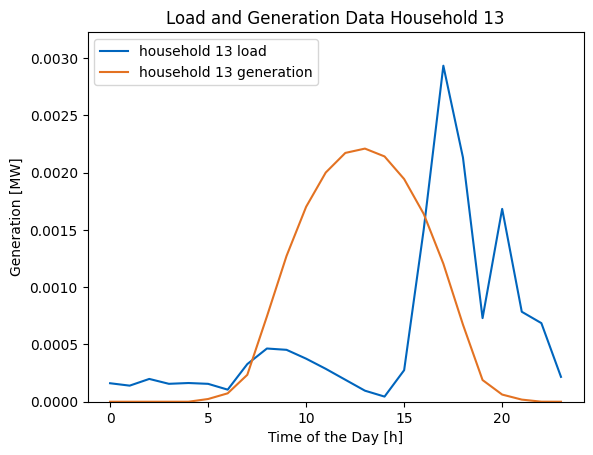

In [123]:
# plot generation data# plot household 13 load and generation data
load_data['13'].plot(legend=True, xlabel="Time of the Day [h]", ylabel="Load [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(0/255,101/255,189/255), label="household 13 load")
gen_data['13'].plot(legend=True, title="Load and Generation Data Household 13", xlabel="Time of the Day [h]", ylabel="Generation [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(227/255,114/255,34/255), label="household 13 generation")

<Axes: title={'center': 'Load and Generation Data Household 6'}, xlabel='Time of the Day [h]', ylabel='Generation [MW]'>

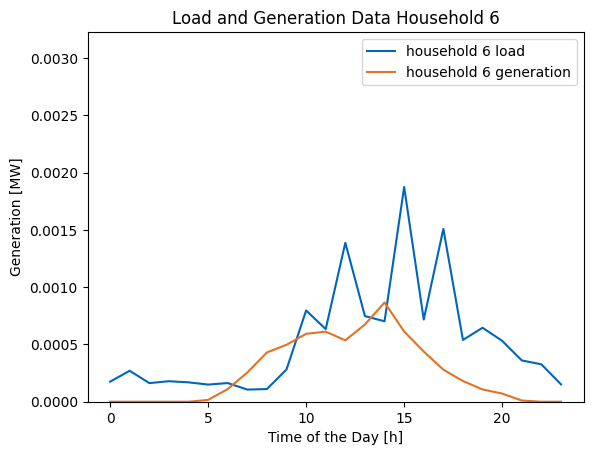

In [124]:
# plot generation data# plot household 6 load and generation data
load_data['6'].plot(legend=True, xlabel="Time of the Day [h]", ylabel="Load [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(0/255,101/255,189/255), label="household 6 load")
gen_data['6'].plot(legend=True, title="Load and Generation Data Household 6", xlabel="Time of the Day [h]", ylabel="Generation [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(227/255,114/255,34/255), label="household 6 generation")

Couple of additional plots are created to show the individual household loads and generation profiles.

In [125]:
# Subtract generation from load for each household and hour
net_load_df = load_data - gen_data
# Show result
net_load_df.head()

household,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,0.000166,0.000163,0.000162,0.000136,0.000177,0.000401,0.000175,0.000154,0.000151,0.000172,0.000173,0.000120,0.000169,0.000161,0.000204,0.000201,0.000178
1,0.000161,0.000170,0.000147,0.000179,0.000162,0.000166,0.000270,0.000146,0.000149,0.000164,0.000141,0.000160,0.000180,0.000140,0.000207,0.000213,0.000188
2,0.000172,0.000161,0.000161,0.000175,0.000239,0.000179,0.000163,0.000151,0.000151,0.000146,0.000143,0.000152,0.000183,0.000199,0.000203,0.000204,0.000166
3,0.000162,0.000181,0.000148,0.000166,0.000197,0.000172,0.000179,0.000154,0.000159,0.000149,0.000147,0.000179,0.000189,0.000156,0.000200,0.000199,0.000182
4,0.000168,0.000173,0.000159,0.000158,0.000156,0.000177,0.000169,0.000142,0.000148,0.000130,0.000138,0.000139,0.000173,0.000163,0.000203,0.000180,0.000182


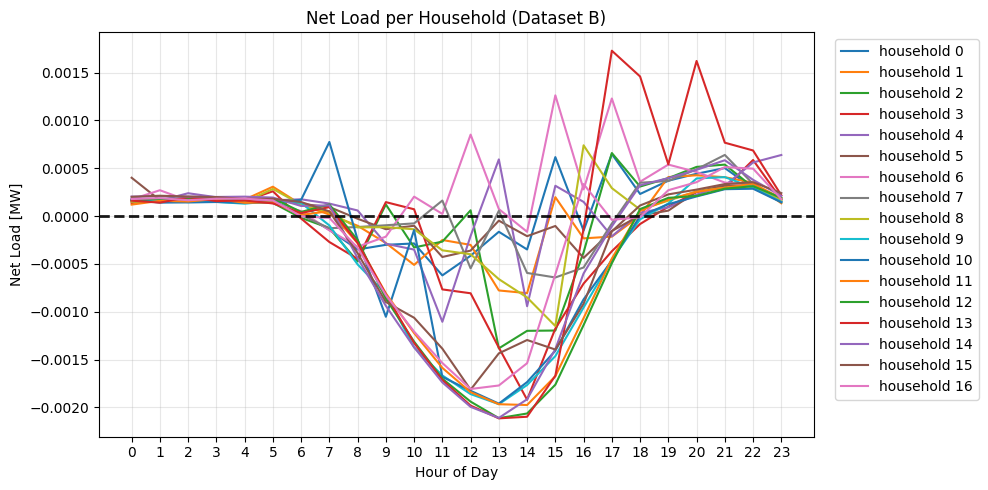

In [126]:
# Plot net load per household (B)
import matplotlib.pyplot as plt

net_load = net_load_df.copy()

# Plot
plt.figure(figsize=(10, 5))
for col in net_load.columns:
    plt.plot(net_load.index, net_load[col], marker=None, label=f"household {col}")
plt.axhline(0, color='black', linewidth=2.0, linestyle='--', alpha=0.9, zorder=5)
plt.title("Net Load per Household (Dataset B)")
plt.xlabel("Hour of Day")
plt.ylabel("Net Load [MW]")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.legend(ncol=1, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In this plot anything above the zero line indicates that the household is taking power from the grid, while anything below indicates that the household is exporting their excess generated power to the grid. We can see that during peak generation hours, many households are exporting power, while during other times they are consuming power. This confirms our earlier observation that peak generation times are likely when the lines are most overloaded, as many households are exporting power simultaneously.

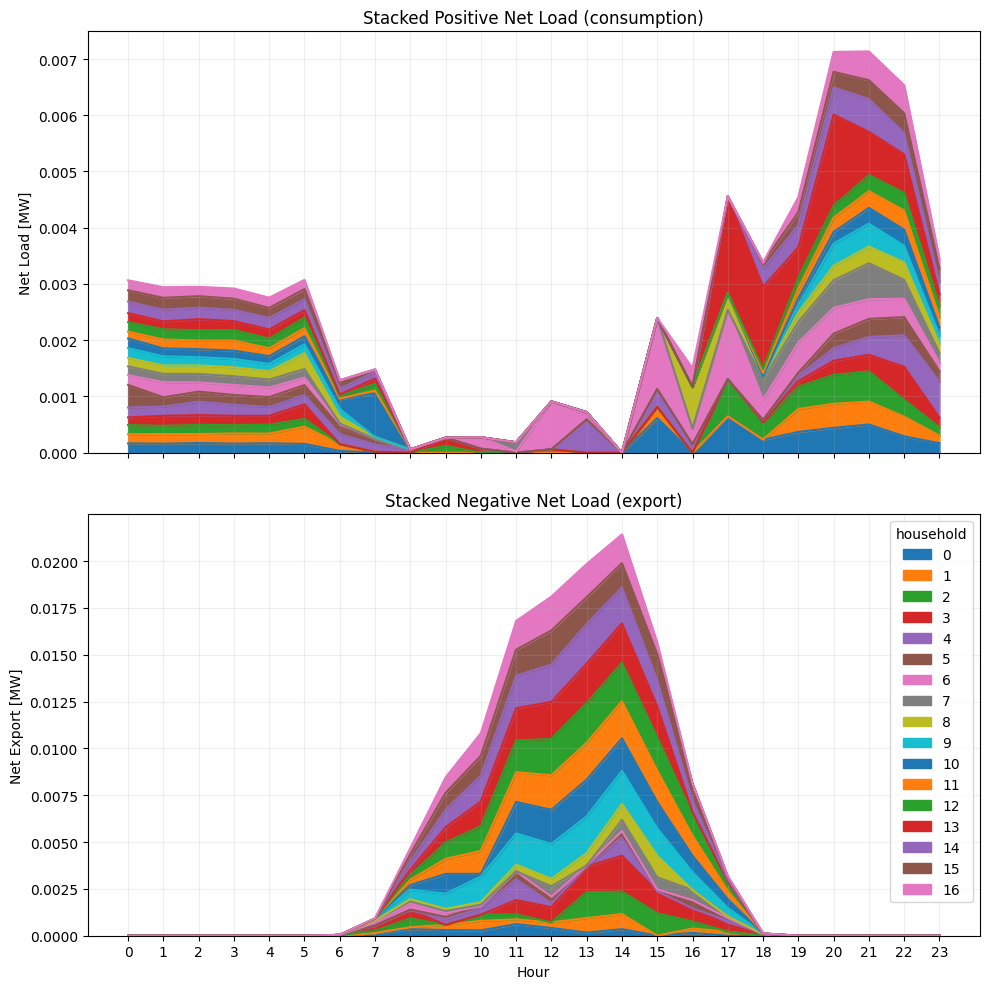

In [127]:
# Clipped stacked plots from net_load_df: positives vs negative magnitudes
import matplotlib.pyplot as plt

# Use only the computed net_load_df (do not reference load_data or gen_data)
net = net_load_df.copy()
# Clip positives and negatives separately
net_pos = net.clip(lower=0)
net_neg_mag = -(net.clip(upper=0))  # convert negatives to positive magnitudes

# Plot two stacked area subplots (positives on top, negative magnitudes below)
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Positive net load (consumption) — no legend on this subplot
net_pos.plot.area(ax=axes[0], stacked=True, title="Stacked Positive Net Load (consumption)", legend=False)
axes[0].set_ylabel("Net Load [MW]")
axes[0].grid(alpha=0.2)

# Negative net load magnitudes (export) - plotted as positive magnitudes
net_neg_mag.plot.area(ax=axes[1], stacked=True, title="Stacked Negative Net Load (export)")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Net Export [MW]")
axes[1].set_xticks(range(0,24))
axes[1].grid(alpha=0.2)


plt.tight_layout()
plt.show()

The top plot shows the cumulative load being imported from the grid (postive values of the net load) and the bottom plot shows the cumulative generation being exported to the grid (negative values). This gives a clear picture of the net power flow at the grid connection point over time. 

This also shows that it is important to place the households with high excess generation capacity in locations where they can effectively reduce the load on the grid during peak times - next to the households that don't completely cover their own load with generation. While also spreading out the households with high excess generation as to not overload the lines in one location during peak generation times.

Now we identify in more detail the self-consumption of generated power for each individual household, specifically which households are the biggest exporters power to the grid, as these are likely the ones contributing most to line overloads.

In [128]:
# Calculate percentage of load covered by generation per hour per household (B)
import pandas as pd
import numpy as np

gen = gen_data.copy()
load = load_data.copy()

# Treat very small values (order e-05) as zero to avoid huge ratios from tiny denominators
threshold = 1e-5
gen = gen.where(gen.abs() >= threshold, 0.0)
load = load.where(load.abs() >= threshold, 0.0)

# Compute percentage: (generation / load) * 100
# Use safe division: where load == 0, result will be NaN unless both are zero.
pct = gen.divide(load).replace([np.inf, -np.inf], np.nan) * 100

# Define convention for zero-load hours:
# - If both generation and load are zero -> coverage = 0%
# - If load == 0 and generation > 0 -> coverage = 100% (generation fully exceeds zero load)
both_zero = (gen == 0) & (load == 0)
load_zero_gen_pos = (load == 0) & (gen > 0)

pct = pct.where(~both_zero, 0.0)
pct = pct.where(~load_zero_gen_pos, 500.0)
print(" Generation coverage (%):")
print(f"{pct}")


 Generation coverage (%):
household           0            1            2            3            4  \
0            0.000000     0.000000     0.000000     0.000000     0.000000   
1            0.000000     0.000000     0.000000     0.000000     0.000000   
2            0.000000     0.000000     0.000000     0.000000     0.000000   
3            0.000000     0.000000     0.000000     0.000000     0.000000   
4            0.000000     0.000000     0.000000     0.000000     0.000000   
5            8.487487     4.975840    14.788852     8.775041     0.000000   
6           80.501925    32.731103   118.398591   127.054152    11.371804   
7          210.483563    88.860475   168.838725   378.643524    31.124383   
8          391.101702   152.740612   814.296418   864.834662    74.509035   
9          207.839171   225.000020    72.583668    47.348893   209.698043   
10         185.284556   361.950462   223.317142    73.994772   234.588619   
11         402.968565   216.188944   166.953676   

In [129]:
# Print mean coverage per household across hours
mean_cov = pct.mean()
# Order households by mean coverage from smallest to largest
mean_cov_sorted = mean_cov.sort_values(ascending=True)
print("\nAverage coverage per household (%) ordered smallest to largest:")
print(mean_cov_sorted)


Average coverage per household (%) ordered smallest to largest:
household
6      61.909430
5      74.109122
0      95.285622
7     101.056601
8     133.968606
1     139.161465
4     160.556276
15    194.743030
2     281.185415
11    317.383719
13    453.124151
3     501.152456
9     518.456515
12    528.033967
16    575.496674
14    606.282521
10    876.271826
dtype: float64


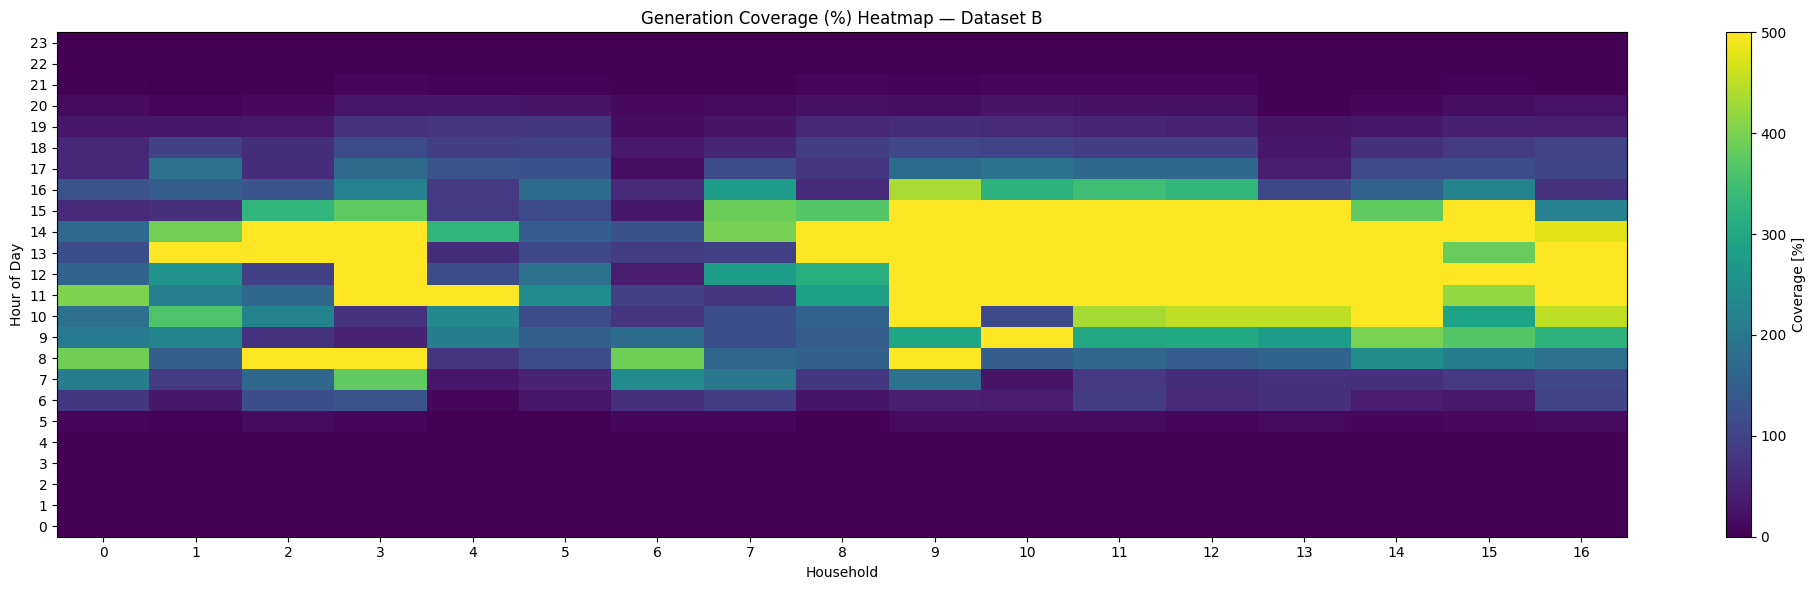

In [130]:
# Heatmap of generation coverage (%) per hour and household (B)

# Load coverage if saved, otherwise try to use in-notebook variables or compute from gen/load
cov = pct.copy()

# Prepare data for heatmap
data = cov.values
n_hours, n_houses = data.shape

# determine hour labels

hours = cov.index.astype(int).tolist()
houses = [str(c) for c in cov.columns]

# Plot heatmap
plt.figure(figsize=(max(6, n_houses * 1.2), 6))
im = plt.imshow(data, aspect='auto', cmap='viridis', origin='lower', vmin=0, vmax=500)
cb = plt.colorbar(im, label='Coverage [%]')
plt.yticks(ticks=range(n_hours), labels=hours)
plt.xticks(ticks=range(n_houses), labels=houses)
plt.xlabel('Household')
plt.ylabel('Hour of Day')
plt.title('Generation Coverage (%) Heatmap — Dataset B')
plt.tight_layout()
plt.show()



Here we calculate the percentage of each household's load that is covered by their own generation at each time step and take an mean average value. This gives us a rough idea of how self-sufficient each household is with their own generation and which households could be placed near each other to reduce line overloads. For example household Nr.6 could be placed near household Nr.12 to help cover its load and reduce line loading. The heatmap helps visualize this data more clearly.

However, our goal is to minimize maximum line loading, so in the next steps we investigate the maximum power import and export per household to identify the households that contribute most to line overloads during peak times. We also calculate the sum total imported and exported power to the power grid to get an idea on how these 17 households interact with the external grid overall.

In [131]:
# Summarize net load: total positive and total negative per household

net = net_load_df.copy()

# Sum positive values (net import to household) and negative values (net export from household)
positive_sum = net.clip(lower=0).sum()  # positive numbers (MWh if hourly sums)
negative_sum = net.clip(upper=0).sum()  # negative numbers (MWh)
negative_sum_abs = -negative_sum  # absolute exported energy (MWh)

# Max values per household (peak import and peak export magnitude)
positive_max = net.clip(lower=0).max()  # peak import (MW) per household
negative_min = net.clip(upper=0).min()  # most negative value (most export) per household
negative_max_abs = -negative_min  # peak export magnitude per household

summary_df = pd.DataFrame({
    "positive_sum_MW_h": positive_sum,
    "negative_sum_MW_h": negative_sum,
    "negative_sum_abs_MW_h": negative_sum_abs,
    "positive_max_MW": positive_max,
    "negative_min_MW": negative_min,
    "negative_max_abs_MW": negative_max_abs
})
#print(summary_df)

print("Per-household Net Load Summary:")
# Summary of sum total imported and exported power per household
for house in summary_df.index:
    pos = summary_df.loc[house, "positive_sum_MW_h"]
    neg_abs = summary_df.loc[house, "negative_sum_abs_MW_h"]
    print(f"Household {house}: Sum from grid = {pos:.6f}, Sum to grid = {neg_abs:.6f}")

# Total imported/exported energy across all households (sum over hours and households)
total_import_MW_h = positive_sum.sum()
total_export_MW_h = negative_sum_abs.sum()
print()
print(f"Total imported energy across all households (sum of positive net load) [MW·h]: {total_import_MW_h:.6f}")
print(f"Total exported energy across all households (sum of absolute negative net load) [MW·h]: {total_export_MW_h:.6f}")
print("\n")
# Sort households by peak import magnitude (descending) so the biggest importers appear first
summary_sorted_pos = summary_df.sort_values("positive_max_MW", ascending=False)

print("Households sorted by peak import magnitude:")
for house in summary_sorted_pos.index:
    pos_max = summary_sorted_pos.loc[house, "positive_max_MW"]
    print(f"Household {house}: Peak import = {pos_max:.6f}")
print("\n")
# Sort households by peak export magnitude (descending) so the biggest exporters appear first
summary_sorted = summary_df.sort_values("negative_max_abs_MW", ascending=False)
for house in summary_sorted.index:
    neg_peak = summary_sorted.loc[house, "negative_max_abs_MW"]
    print(f"Household {house}: Peak export = {neg_peak:.6f}")

Per-household Net Load Summary:
Household 0: Sum from grid = 0.004289, Sum to grid = 0.002778
Household 1: Sum from grid = 0.003218, Sum to grid = 0.003474
Household 2: Sum from grid = 0.003963, Sum to grid = 0.005370
Household 3: Sum from grid = 0.002696, Sum to grid = 0.007943
Household 4: Sum from grid = 0.004387, Sum to grid = 0.003106
Household 5: Sum from grid = 0.002643, Sum to grid = 0.002008
Household 6: Sum from grid = 0.007252, Sum to grid = 0.000848
Household 7: Sum from grid = 0.003481, Sum to grid = 0.002810
Household 8: Sum from grid = 0.003490, Sum to grid = 0.003788
Household 9: Sum from grid = 0.002434, Sum to grid = 0.012954
Household 10: Sum from grid = 0.002871, Sum to grid = 0.011390
Household 11: Sum from grid = 0.002262, Sum to grid = 0.012867
Household 12: Sum from grid = 0.002511, Sum to grid = 0.013637
Household 13: Sum from grid = 0.008101, Sum to grid = 0.012136
Household 14: Sum from grid = 0.003806, Sum to grid = 0.012602
Household 15: Sum from grid = 0.0

From the results we can see that a lot more power is flowing in the grid during peak generation times. Households 13, 12 and 14 are the biggest exporters with a peak export of over 0.0021 MW. However, households 13 and 6 are also significant importers at the peak demand compared to all other households.

The next step is to rearrange the households in the grid layout to minimize line loading during these peak import and export times, by placing high exporters next to high importers and spreading out the high exporters to avoid overloading lines during peak generation and demand times. The first attempt for this will be done manually to perform a time series simulation of the grid, develop a baseline, identify potential improvements and explore options for the further optimization using machine learning algorithms.